Loading data...
                            OLS Regression Results                            
Dep. Variable:           log_quantity   R-squared:                       0.003
Model:                            OLS   Adj. R-squared:                 -0.009
Method:                 Least Squares   F-statistic:                    0.2820
Date:                Mon, 19 Oct 2026   Prob (F-statistic):              0.597
Time:                        16:06:53   Log-Likelihood:                -80.665
No. Observations:                  86   AIC:                             165.3
Df Residuals:                      84   BIC:                             170.2
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          3.7058      1.581    

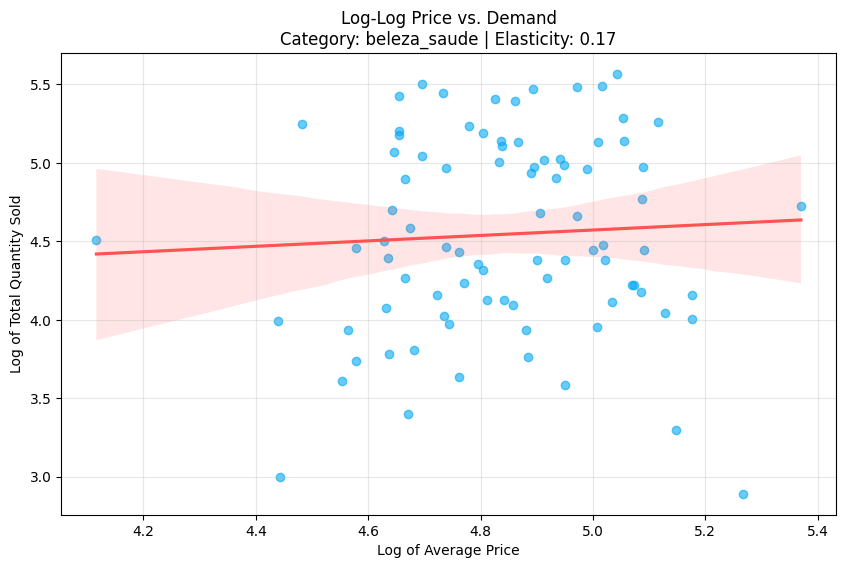

In [2]:
#Model 1

import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load the datasets
print("Loading data...")
items = pd.read_csv('olist_order_items_dataset.csv')
orders = pd.read_csv('olist_orders_dataset.csv')
products = pd.read_csv('olist_products_dataset.csv')

# 2. Merge datasets to link price, timestamps, and product categories
df = items.merge(orders[['order_id', 'order_purchase_timestamp']], on='order_id')
df = df.merge(products[['product_id', 'product_category_name']], on='product_id')

# Convert timestamp to datetime objects
df['order_purchase_timestamp'] = pd.to_datetime(df['order_purchase_timestamp'])

# 3. Filter for a specific category
# Elasticity is only meaningful within similar product groupings
category = 'beleza_saude' # Health and Beauty
cat_df = df[df['product_category_name'] == category].copy()

# 4. Aggregate data by week to model shifts over time
cat_df['week'] = cat_df['order_purchase_timestamp'].dt.to_period('W').dt.start_time
weekly_data = cat_df.groupby('week').agg(
    total_quantity=('order_item_id', 'count'),
    avg_price=('price', 'mean')
).reset_index()

# Filter out early weeks with anomalous low volume to avoid skewed logs
weekly_data = weekly_data[weekly_data['total_quantity'] > 10]

# 5. Log-Log Transformation
weekly_data['log_quantity'] = np.log(weekly_data['total_quantity'])
weekly_data['log_price'] = np.log(weekly_data['avg_price'])

# 6. Fit the Ordinary Least Squares (OLS) Regression Model
X = weekly_data['log_price']
X = sm.add_constant(X) # Adds the intercept (alpha)
y = weekly_data['log_quantity']

model = sm.OLS(y, X).fit()
print(model.summary())

# Extract the elasticity coefficient (beta)
elasticity = model.params['log_price']
print(f"\n--- Results ---")
print(f"Price Elasticity for '{category}': {elasticity:.2f}")

if elasticity < -1:
    print("Verdict: Elastic. Consumers are highly sensitive to price changes.")
elif -1 <= elasticity < 0:
    print("Verdict: Inelastic. Consumers will still buy even if prices rise slightly.")
else:
    print("Verdict: Atypical (Positive). Price increases correlate with demand increases (check for seasonality or confounding variables).")

# 7. Visualize the relationship
plt.figure(figsize=(10, 6))
sns.regplot(
    x='log_price',
    y='log_quantity',
    data=weekly_data,
    scatter_kws={'alpha':0.6, 'color': '#03a9f4'},
    line_kws={'color': '#ff5252'}
)
plt.title(f'Log-Log Price vs. Demand\nCategory: {category} | Elasticity: {elasticity:.2f}')
plt.xlabel('Log of Average Price')
plt.ylabel('Log of Total Quantity Sold')
plt.grid(True, alpha=0.3)
plt.show()

In [3]:
#Model 2

import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load the datasets
print("Loading data...")
items = pd.read_csv('olist_order_items_dataset.csv')
orders = pd.read_csv('olist_orders_dataset.csv')
products = pd.read_csv('olist_products_dataset.csv')

# 2. Merge datasets to link price, timestamps, and product categories
df = items.merge(orders[['order_id', 'order_purchase_timestamp']], on='order_id')
df = df.merge(products[['product_id', 'product_category_name']], on='product_id')
df['order_purchase_timestamp'] = pd.to_datetime(df['order_purchase_timestamp'])

# 3. Filter for a specific category
category = 'beleza_saude' # Health and Beauty
cat_df = df[df['product_category_name'] == category].copy()

# 4. Aggregate data by week
cat_df['week'] = cat_df['order_purchase_timestamp'].dt.to_period('W').dt.start_time
weekly_data = cat_df.groupby('week').agg(
    total_quantity=('order_item_id', 'count'),
    avg_price=('price', 'mean'),
    avg_freight=('freight_value', 'mean') # NEW: Added freight cost
).reset_index()

# Filter out early anomalous weeks
weekly_data = weekly_data[weekly_data['total_quantity'] > 10].copy()
weekly_data = weekly_data.sort_values('week').reset_index(drop=True)

# 5. NEW: Feature Engineering for Time and Seasonality
# week_number captures Olist's organic platform growth over time (1, 2, 3...)
weekly_data['week_number'] = weekly_data.index + 1

# is_november captures the massive Black Friday seasonal surges in Brazil
weekly_data['is_november'] = (weekly_data['week'].dt.month == 11).astype(int)

# 6. Log Transformations
weekly_data['log_quantity'] = np.log(weekly_data['total_quantity'])
weekly_data['log_price'] = np.log(weekly_data['avg_price'])
weekly_data['log_freight'] = np.log(weekly_data['avg_freight']) # NEW: Log of freight

# 7. Fit the Multivariable OLS Regression
features = ['log_price', 'log_freight', 'week_number', 'is_november']
X = weekly_data[features]
X = sm.add_constant(X)
y = weekly_data['log_quantity']

model = sm.OLS(y, X).fit()
print(model.summary())

# 8. Print readable insights
print("\n" + "="*50)
print("MULTIVARIABLE REGRESSION INSIGHTS")
print("="*50)

def interpret_p(p_val, coef, name):
    sig = "Significant" if p_val < 0.05 else "Not Significant"
    return f"{name}: {coef:.3f} (p={p_val:.3f}) -> {sig}"

print(interpret_p(model.pvalues['log_price'], model.params['log_price'], "Price Elasticity"))
print(interpret_p(model.pvalues['log_freight'], model.params['log_freight'], "Freight Elasticity"))
print(interpret_p(model.pvalues['week_number'], model.params['week_number'], "Platform Growth Trend"))
print(interpret_p(model.pvalues['is_november'], model.params['is_november'], "November Surge Multiplier"))
print(f"\nModel Explanatory Power (R-squared): {model.rsquared:.3f} (Target: Closer to 1.0 is better)")

Loading data...
                            OLS Regression Results                            
Dep. Variable:           log_quantity   R-squared:                       0.691
Model:                            OLS   Adj. R-squared:                  0.676
Method:                 Least Squares   F-statistic:                     45.33
Date:                Mon, 19 Oct 2026   Prob (F-statistic):           6.21e-20
Time:                        16:07:11   Log-Likelihood:                -30.278
No. Observations:                  86   AIC:                             70.56
Df Residuals:                      81   BIC:                             82.83
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
const           2.2127      0.918 

In [5]:
#Model 3

import pandas as pd
import numpy as np
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

# 1. Ensure product_weight_g is in your merged dataset
df = items.merge(orders[['order_id', 'order_purchase_timestamp']], on='order_id')
df = df.merge(products[['product_id', 'product_category_name', 'product_weight_g']], on='product_id')
df['order_purchase_timestamp'] = pd.to_datetime(df['order_purchase_timestamp'])

# 2. Filter category and aggregate (Now including weight)
category = 'beleza_saude'
cat_df = df[df['product_category_name'] == category].copy()

cat_df['week'] = cat_df['order_purchase_timestamp'].dt.to_period('W').dt.start_time
weekly_data = cat_df.groupby('week').agg(
    total_quantity=('order_item_id', 'count'),
    avg_price=('price', 'mean'),
    avg_freight=('freight_value', 'mean'),
    avg_weight=('product_weight_g', 'mean') # NEW: Product weight
).reset_index()

weekly_data = weekly_data[weekly_data['total_quantity'] > 10].copy()
weekly_data = weekly_data.sort_values('week').reset_index(drop=True)

# 3. Feature Engineering & Log Transforms
weekly_data['week_number'] = weekly_data.index + 1
weekly_data['is_november'] = (weekly_data['week'].dt.month == 11).astype(int)

weekly_data['log_quantity'] = np.log(weekly_data['total_quantity'])
weekly_data['log_price'] = np.log(weekly_data['avg_price'])
weekly_data['log_freight'] = np.log(weekly_data['avg_freight'])
weekly_data['log_weight'] = np.log(weekly_data['avg_weight']) # NEW: Log of weight

# ---------------------------------------------------------
# DIAGNOSTIC: Check Variance Inflation Factor (VIF)
# ---------------------------------------------------------
print("="*50)
print("MULTICOLLINEARITY CHECK (VIF)")
print("="*50)

# We check VIF on the variables before adding the constant
X_vif = weekly_data[['log_price', 'log_freight', 'log_weight', 'week_number', 'is_november']]

vif_data = pd.DataFrame()
vif_data["Feature"] = X_vif.columns
vif_data["VIF Score"] = [variance_inflation_factor(X_vif.values, i) for i in range(len(X_vif.columns))]
print(vif_data.to_string(index=False))
print("\n*Rule of thumb: VIF > 5 indicates problematic multicollinearity.*\n")

# ---------------------------------------------------------
# THE FIX: Run New Regression with Weight Controlled
# ---------------------------------------------------------
print("="*50)
print("UPDATED REGRESSION (CONTROLLING FOR WEIGHT)")
print("="*50)

X = sm.add_constant(X_vif)
y = weekly_data['log_quantity']

model = sm.OLS(y, X).fit()
print(model.summary())

MULTICOLLINEARITY CHECK (VIF)
    Feature  VIF Score
  log_price   1.819997
log_freight   3.220730
 log_weight   2.976454
week_number   1.294391
is_november   1.023668

*Rule of thumb: VIF > 5 indicates problematic multicollinearity.*

UPDATED REGRESSION (CONTROLLING FOR WEIGHT)
                            OLS Regression Results                            
Dep. Variable:           log_quantity   R-squared:                       0.693
Model:                            OLS   Adj. R-squared:                  0.673
Method:                 Least Squares   F-statistic:                     36.03
Date:                Mon, 19 Oct 2026   Prob (F-statistic):           3.81e-19
Time:                        16:11:27   Log-Likelihood:                -30.100
No. Observations:                  86   AIC:                             72.20
Df Residuals:                      80   BIC:                             86.93
Df Model:                           5                                         
Covarianc

Loading data...
TRUE PRICE ELASTICITY MODEL (beleza_saude in SP)
                            OLS Regression Results                            
Dep. Variable:           log_quantity   R-squared:                       0.769
Model:                            OLS   Adj. R-squared:                  0.757
Method:                 Least Squares   F-statistic:                     67.26
Date:                Mon, 19 Oct 2026   Prob (F-statistic):           5.80e-25
Time:                        16:15:05   Log-Likelihood:                -30.827
No. Observations:                  86   AIC:                             71.65
Df Residuals:                      81   BIC:                             83.93
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------

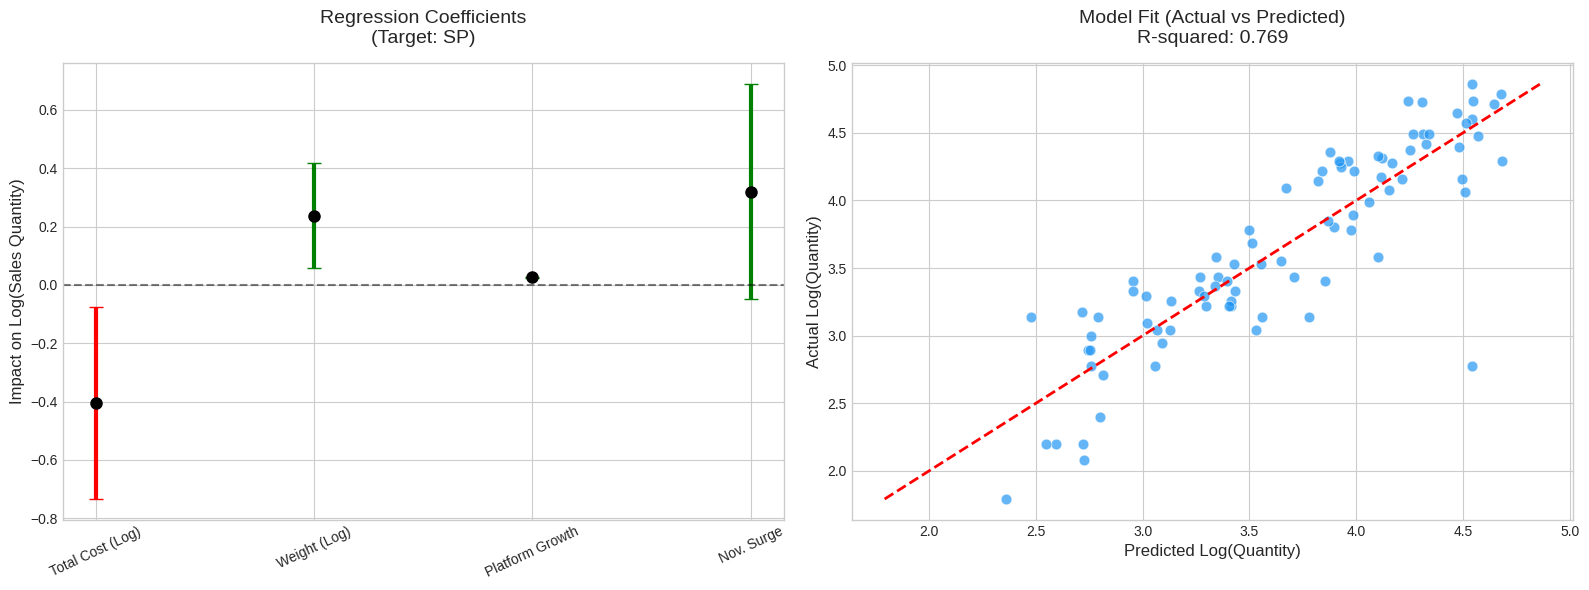

In [8]:
#Model 4

import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load the Datasets (Now including customers)
print("Loading data...")
items = pd.read_csv('olist_order_items_dataset.csv')
orders = pd.read_csv('olist_orders_dataset.csv')
products = pd.read_csv('olist_products_dataset.csv')
customers = pd.read_csv('olist_customers_dataset.csv') # NEW

# 2. Merge Datasets to link orders, products, and customer geography
df = items.merge(orders[['order_id', 'customer_id', 'order_purchase_timestamp']], on='order_id')
df = df.merge(customers[['customer_id', 'customer_state']], on='customer_id') # NEW
df = df.merge(products[['product_id', 'product_category_name', 'product_weight_g']], on='product_id')

df['order_purchase_timestamp'] = pd.to_datetime(df['order_purchase_timestamp'])

# 3. Filter for Category AND State (Geographic Isolation)
category = 'beleza_saude'
state = 'SP' # São Paulo
cat_df = df[(df['product_category_name'] == category) & (df['customer_state'] == state)].copy()

# 4. Aggregate Weekly Data
cat_df['week'] = cat_df['order_purchase_timestamp'].dt.to_period('W').dt.start_time
weekly_data = cat_df.groupby('week').agg(
    total_quantity=('order_item_id', 'count'),
    avg_price=('price', 'mean'),
    avg_freight=('freight_value', 'mean'),
    avg_weight=('product_weight_g', 'mean')
).reset_index()

# Filter out sparse early weeks and sort
weekly_data = weekly_data[weekly_data['total_quantity'] > 5].copy() # Lowered threshold for single-state volume
weekly_data = weekly_data.sort_values('week').reset_index(drop=True)

# 5. Feature Engineering (The "Total Landed Cost" Fix)
weekly_data['week_number'] = weekly_data.index + 1
weekly_data['is_november'] = (weekly_data['week'].dt.month == 11).astype(int)
weekly_data['total_cost'] = weekly_data['avg_price'] + weekly_data['avg_freight'] # NEW

# 6. Log Transformations
weekly_data['log_quantity'] = np.log(weekly_data['total_quantity'])
weekly_data['log_total_cost'] = np.log(weekly_data['total_cost']) # NEW
weekly_data['log_weight'] = np.log(weekly_data['avg_weight'])

# 7. Fit the Multivariable OLS Regression
X = weekly_data[['log_total_cost', 'log_weight', 'week_number', 'is_november']]
X = sm.add_constant(X)
y = weekly_data['log_quantity']

model = sm.OLS(y, X).fit()
print("="*60)
print(f"TRUE PRICE ELASTICITY MODEL ({category} in {state})")
print("="*60)
print(model.summary())

# 8. Print Clean Insights
print("\n" + "="*60)
print("FINAL BUSINESS INSIGHTS")
print("="*60)

elasticity = model.params['log_total_cost']
p_val = model.pvalues['log_total_cost']
sig = "Significant" if p_val < 0.05 else "Not Significant"

print(f"Total Landed Cost Elasticity: {elasticity:.3f} (p={p_val:.3f}) -> {sig}")
if p_val < 0.05 and elasticity < 0:
    print(f"Verdict: A 10% increase in total cost (price+freight) drops demand by {abs(elasticity)*10:.1f}%.")
else:
    print("Verdict: Even isolated by state, consumers in this category are highly brand/product loyal, not price sensitive.")

# 9. Visualizations
plt.style.use('seaborn-v0_8-whitegrid')
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# --- Plot 1: Coefficient Forest Plot ---
params = model.params.drop('const')
conf = model.conf_int().drop('const')
errors = params - conf[0]

# FIX: Loop through each parameter to apply individual colors safely
for i, (param_name, coef) in enumerate(params.items()):
    color = 'red' if coef < 0 else 'green'
    axes[0].errorbar(x=i, y=coef, yerr=errors[param_name], fmt='o', color='black',
                     ecolor=color, elinewidth=3, capsize=5, markersize=8)

axes[0].axhline(y=0, color='black', linestyle='--', alpha=0.5)
axes[0].set_xticks(range(len(params)))
axes[0].set_xticklabels(['Total Cost (Log)', 'Weight (Log)', 'Platform Growth', 'Nov. Surge'], rotation=25)
axes[0].set_title(f'Regression Coefficients\n(Target: {state})', fontsize=14, pad=15)
axes[0].set_ylabel('Impact on Log(Sales Quantity)', fontsize=12)

# --- Plot 2: Actual vs Predicted Plot ---
sns.scatterplot(x=model.fittedvalues, y=y, ax=axes[1], alpha=0.7, color='#2196f3', s=60)
min_val = min(model.fittedvalues.min(), y.min())
max_val = max(model.fittedvalues.max(), y.max())
axes[1].plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=2)
axes[1].set_title(f'Model Fit (Actual vs Predicted)\nR-squared: {model.rsquared:.3f}', fontsize=14, pad=15)
axes[1].set_xlabel('Predicted Log(Quantity)', fontsize=12)
axes[1].set_ylabel('Actual Log(Quantity)', fontsize=12)

plt.tight_layout()
plt.show()

OPTIMAL PRICE ANALYSIS
Current Baseline: Price = $100.00 | Profit = $30,000.00
Optimal Strategy: Price = $200.00 | Profit = $60,460.80
Impact: By changing the price to $200.00, profit increases by $30,460.80


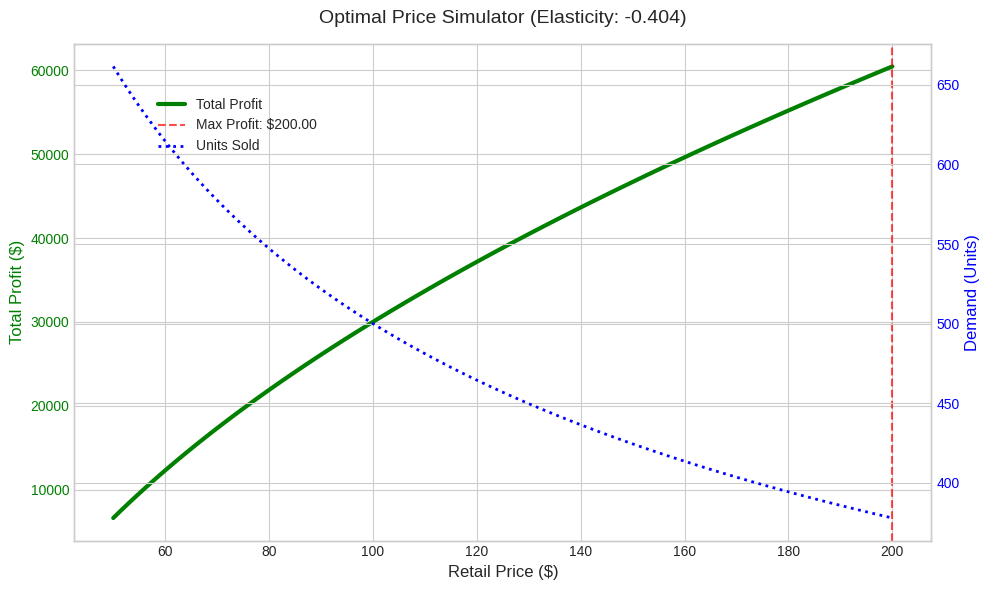

In [10]:
#Optimal price simulator

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as plt_sns

def simulate_optimal_price(base_price, base_volume, unit_cost, elasticity):
    """
    Simulates demand, revenue, and profit across a range of price points
    to find the profit-maximizing price.
    """
    # Create an array of simulated prices (from 50% discount to 100% markup)
    simulated_prices = np.linspace(base_price * 0.5, base_price * 2.0, 100)

    # Calculate demand for each price point using the elasticity formula:
    # Q_new = Q_old * (P_new / P_old) ^ Elasticity
    simulated_demand = base_volume * (simulated_prices / base_price) ** elasticity

    # Calculate financial metrics
    revenue = simulated_prices * simulated_demand
    total_costs = unit_cost * simulated_demand
    profit = revenue - total_costs

    # Compile into a DataFrame
    df_sim = pd.DataFrame({
        'Price': simulated_prices,
        'Demand': simulated_demand,
        'Revenue': revenue,
        'Profit': profit
    })

    # Find the optimal point (maximum profit)
    optimal_row = df_sim.loc[df_sim['Profit'].idxmax()]

    return df_sim, optimal_row

# --- Run the Simulation ---
# Assuming some baseline metrics for a typical "Health & Beauty" product
BASE_PRICE = 100.00       # Current retail price
BASE_VOLUME = 500         # Current weekly units sold
UNIT_COST = 40.00         # Supplier cost to Olist/Seller
ELASTICITY = -0.404       # Our derived coefficient

df_sim, optimal = simulate_optimal_price(BASE_PRICE, BASE_VOLUME, UNIT_COST, ELASTICITY)

print("="*50)
print("OPTIMAL PRICE ANALYSIS")
print("="*50)
print(f"Current Baseline: Price = ${BASE_PRICE:.2f} | Profit = ${(BASE_PRICE - UNIT_COST)*BASE_VOLUME:,.2f}")
print(f"Optimal Strategy: Price = ${optimal['Price']:.2f} | Profit = ${optimal['Profit']:,.2f}")
print(f"Impact: By changing the price to ${optimal['Price']:.2f}, profit increases by ${(optimal['Profit'] - ((BASE_PRICE - UNIT_COST)*BASE_VOLUME)):,.2f}")

# --- Visualization ---
plt.style.use('seaborn-v0_8-whitegrid')
fig, ax1 = plt.subplots(figsize=(10, 6))

# Plot Profit curve
ax1.plot(df_sim['Price'], df_sim['Profit'], color='green', linewidth=3, label='Total Profit')
ax1.set_xlabel('Retail Price ($)', fontsize=12)
ax1.set_ylabel('Total Profit ($)', color='green', fontsize=12)
ax1.tick_params(axis='y', labelcolor='green')

# Mark the optimal price point
ax1.axvline(x=optimal['Price'], color='red', linestyle='--', alpha=0.7, label=f"Max Profit: ${optimal['Price']:.2f}")

# Create a secondary axis for Demand
ax2 = ax1.twinx()
ax2.plot(df_sim['Price'], df_sim['Demand'], color='blue', linewidth=2, linestyle=':', label='Units Sold')
ax2.set_ylabel('Demand (Units)', color='blue', fontsize=12)
ax2.tick_params(axis='y', labelcolor='blue')

plt.title('Optimal Price Simulator (Elasticity: -0.404)', fontsize=14, pad=15)
fig.legend(loc="upper left", bbox_to_anchor=(0.15,0.85))
plt.tight_layout()
plt.show()

Figure 1

The Blue Dotted Line (Demand): As you increase the price from USD 50 to USD 200, the number of units sold does drop (from over 650 units down to just under 400). However, because the demand is inelastic (E=−0.404), this drop is relatively slow and shallow.   

The Green Solid Line (Profit): Because you lose customers so slowly when you raise prices, the extra profit you make on every remaining item vastly outweighs the profit lost from the few customers who walked away. As a result, your total profit climbs continuously as the price increases.   

The Red Dashed Line (The "Optimal" Price): The simulator flagged USD 200.00 as the max profit. However, notice that the green profit curve hasn't actually peaked or started to curve downward—it just hit the right edge of the chart. The script identified USD 200 as the maximum simply because our code only simulated prices up to 200 percent of the USD 100 base price.

In [12]:
#Dynamic Pricing Strategy

import pandas as pd
import numpy as np

# 1. Load All Datasets (Corrected)
print("Loading data for regional dynamic pricing...")
items = pd.read_csv('olist_order_items_dataset.csv')
orders = pd.read_csv('olist_orders_dataset.csv')
products = pd.read_csv('olist_products_dataset.csv')
sellers = pd.read_csv('olist_sellers_dataset.csv') # ADDED

# 2. Merge Data
df = items.merge(orders[['order_id', 'order_purchase_timestamp']], on='order_id')
df = df.merge(products[['product_id', 'product_category_name']], on='product_id')
df = df.merge(sellers[['seller_id', 'seller_state']], on='seller_id') # ADDED
df['order_purchase_timestamp'] = pd.to_datetime(df['order_purchase_timestamp'])
df['month'] = df['order_purchase_timestamp'].dt.month

# ---------------------------------------------------------
# UPGRADED FEATURE: Regional Competitor Density
# ---------------------------------------------------------
# Count unique sellers per category AND per state
regional_density = df.groupby(['product_category_name', 'seller_state'])['seller_id'].nunique().reset_index()
regional_density.rename(columns={'seller_id': 'regional_seller_count'}, inplace=True)

# Calculate percentiles state-by-state rather than nationally
def get_regional_competition_multiplier(row):
    # Find the average number of sellers for this specific category across all states
    state_avg = regional_density[regional_density['product_category_name'] == row['product_category_name']]['regional_seller_count'].mean()

    if row['regional_seller_count'] > (state_avg * 1.5):
        return 0.95 # Saturated state (e.g., SP): 5% discount to win Buy Box
    elif row['regional_seller_count'] < (state_avg * 0.5):
        return 1.05 # Sparse state (e.g., AM, BA): 5% premium for regional monopoly
    return 1.00     # Normal competition

regional_density['comp_multiplier'] = regional_density.apply(get_regional_competition_multiplier, axis=1)

# ---------------------------------------------------------
# FEATURE 2: Seasonality Index
# ---------------------------------------------------------
monthly_volume = df.groupby('month')['order_id'].count()
seasonality_index = (monthly_volume / monthly_volume.mean()).to_dict()

# ---------------------------------------------------------
# ALGORITHM: Regional Dynamic Pricing Engine
# ---------------------------------------------------------
def calculate_regional_dynamic_price(base_price, category, state, month, current_demand, baseline_demand):
    season_multiplier = 1.0 + ((seasonality_index.get(month, 1.0) - 1.0) * 0.1)

    # Fetch regional competition multiplier
    cat_state_data = regional_density[(regional_density['product_category_name'] == category) &
                                      (regional_density['seller_state'] == state)]
    comp_multiplier = cat_state_data['comp_multiplier'].values[0] if not cat_state_data.empty else 1.05 # Default premium if 0 competitors

    demand_ratio = current_demand / baseline_demand if baseline_demand > 0 else 1.0
    demand_multiplier = 1.0 + ((demand_ratio - 1.0) * 0.1)

    dynamic_price = base_price * season_multiplier * comp_multiplier * demand_multiplier
    return round(dynamic_price, 2), season_multiplier, comp_multiplier, demand_multiplier

# --- Test the Upgraded Algorithm ---
target_category = 'beleza_saude'
test_state = 'AM' # Amazonas (Remote state, low competition)
test_base_price = 100.00

final_price, s_mult, c_mult, d_mult = calculate_regional_dynamic_price(
    base_price=test_base_price,
    category=target_category,
    state=test_state,
    month=11,
    current_demand=150,
    baseline_demand=100
)

print("\n" + "="*50)
print(f"REGIONAL PRICING: {target_category.upper()} in {test_state}")
print("="*50)
print(f"Base Price:           ${test_base_price:.2f}")
print(f"Seasonality (Nov):    x{s_mult:.2f}")
print(f"Regional Comp Factor: x{c_mult:.2f} (Adjusted for {test_state})")
print(f"Real-Time Surge:      x{d_mult:.2f}")
print("-" * 50)
print(f"FINAL DYNAMIC PRICE:  ${final_price:.2f}")

Loading data for regional dynamic pricing...

REGIONAL PRICING: BELEZA_SAUDE in AM
Base Price:           $100.00
Seasonality (Nov):    x0.99
Regional Comp Factor: x1.05 (Adjusted for AM)
Real-Time Surge:      x1.05
--------------------------------------------------
FINAL DYNAMIC PRICE:  $109.40


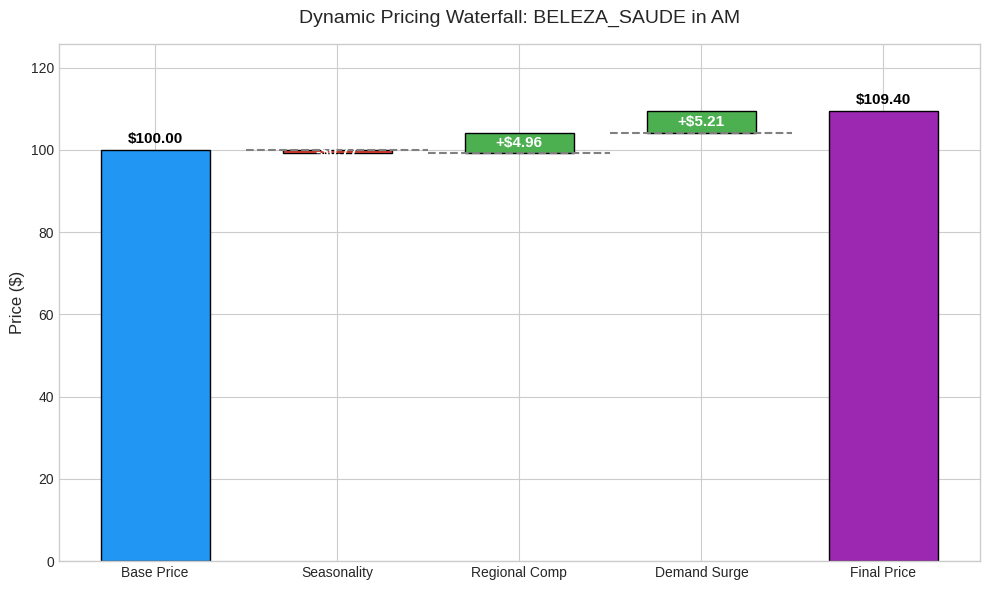

In [13]:
#Visualizing dynamic pricing

import matplotlib.pyplot as plt

# 1. Calculate the sequential dollar impact of each multiplier
step1_price = test_base_price * s_mult
step2_price = step1_price * c_mult
final_calculated_price = step2_price * d_mult

impact_season = step1_price - test_base_price
impact_comp = step2_price - step1_price
impact_surge = final_calculated_price - step2_price

# 2. Prepare data for the Waterfall Chart
labels = ['Base Price', 'Seasonality', 'Regional Comp', 'Demand Surge', 'Final Price']
impact_values = [test_base_price, impact_season, impact_comp, impact_surge, final_calculated_price]

# Calculate where each bar should start (the 'bottom' parameter)
bottoms = [
    0,
    test_base_price,
    step1_price,
    step2_price,
    0  # Final price starts at 0 to show total height
]

# Color coding: Blue for base/final, Green for positive impacts, Red for negative impacts
colors = [
    '#2196f3',
    '#f44336' if impact_season < 0 else '#4caf50',
    '#f44336' if impact_comp < 0 else '#4caf50',
    '#f44336' if impact_surge < 0 else '#4caf50',
    '#9c27b0'
]

# 3. Build the Visualization
plt.style.use('seaborn-v0_8-whitegrid')
fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(labels, impact_values, bottom=bottoms, color=colors, edgecolor='black', width=0.6)

# 4. Add data labels to the bars
for i, bar in enumerate(bars):
    # Determine label format (add a '+' for positive adjustments)
    val = impact_values[i]
    if i in [1, 2, 3]: # Adjustments
        label_text = f"+${val:.2f}" if val > 0 else f"-${abs(val):.2f}"
    else: # Base and Final
        label_text = f"${val:.2f}"

    # Place label at the center of each bar block
    y_pos = bottoms[i] + (val / 2) if i in [1, 2, 3] else val + 1

    ax.text(bar.get_x() + bar.get_width()/2, y_pos, label_text,
            ha='center', va='center' if i in [1,2,3] else 'bottom',
            color='white' if i in [1, 2, 3] else 'black', fontweight='bold', fontsize=11)

# Format axes
ax.set_ylabel('Price ($)', fontsize=12)
ax.set_title(f'Dynamic Pricing Waterfall: {target_category.upper()} in {test_state}', fontsize=14, pad=15)
ax.set_ylim(0, final_calculated_price * 1.15) # Add headroom for labels

# Draw connecting lines between the steps
for i in range(1, 4):
    ax.plot([i-0.5, i+0.5], [bottoms[i], bottoms[i]], color='gray', linestyle='--')

plt.tight_layout()
plt.show()

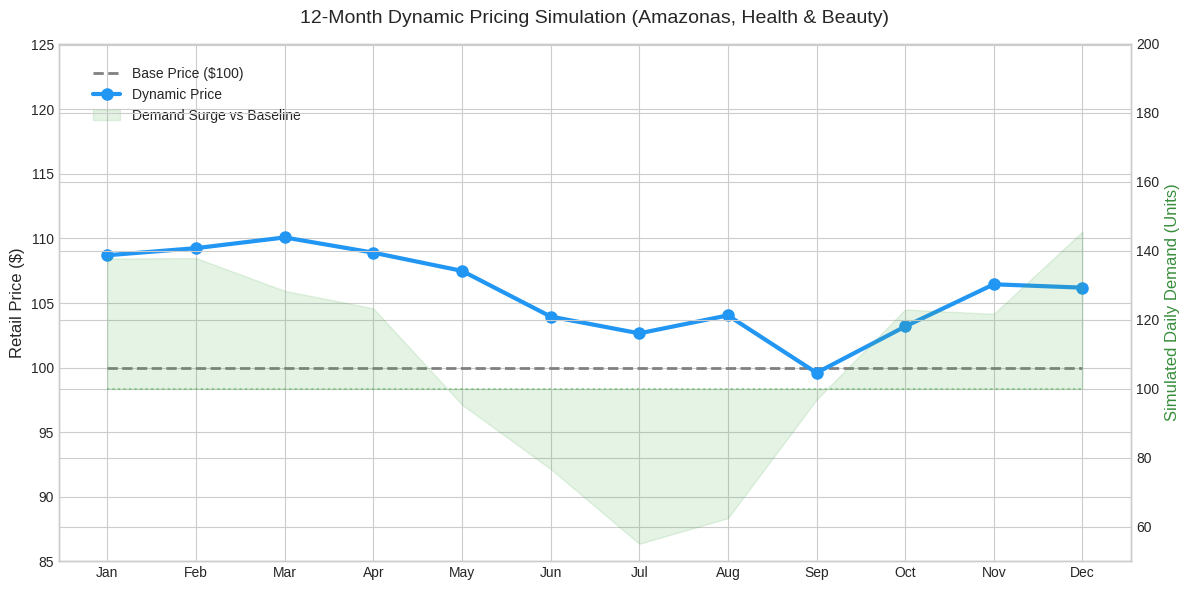

In [14]:
#Simulating dynamic pricing engine

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Setup the Simulation Parameters
months = list(range(1, 13))
month_names = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
base_price = 100.00
baseline_demand = 100

dynamic_prices = []
season_mults = []
surge_mults = []

# Generate a synthetic demand curve (e.g., peaks in May and November)
np.random.seed(42)
simulated_demands = [100 + (np.sin(m/1.5) * 40) + np.random.randint(-15, 20) for m in months]

# 2. Run the 12-Month Simulation
for i, m in enumerate(months):
    current_demand = simulated_demands[i]

    # Call the algorithm from the previous cell
    final_price, s_mult, c_mult, d_mult = calculate_regional_dynamic_price(
        base_price=base_price,
        category='beleza_saude',
        state='AM',
        month=m,
        current_demand=current_demand,
        baseline_demand=baseline_demand
    )

    dynamic_prices.append(final_price)
    season_mults.append(s_mult)
    surge_mults.append(d_mult)

# 3. Build the Time-Series Visualization
plt.style.use('seaborn-v0_8-whitegrid')
fig, ax1 = plt.subplots(figsize=(12, 6))

# Plot the base price and dynamic price
ax1.plot(month_names, [base_price]*12, color='gray', linestyle='--', linewidth=2, label='Base Price ($100)')
ax1.plot(month_names, dynamic_prices, color='#2196f3', marker='o', linewidth=3, markersize=8, label='Dynamic Price')

ax1.set_ylabel('Retail Price ($)', fontsize=12)
ax1.set_ylim(85, max(dynamic_prices) + 15)
ax1.set_title('12-Month Dynamic Pricing Simulation (Amazonas, Health & Beauty)', fontsize=14, pad=15)

# Add a secondary axis for the Demand Surge background
ax2 = ax1.twinx()
ax2.fill_between(month_names, simulated_demands, 100, color='#4caf50', alpha=0.15, label='Demand Surge vs Baseline')
ax2.plot(month_names, [100]*12, color='#4caf50', linestyle=':', alpha=0.5)
ax2.set_ylabel('Simulated Daily Demand (Units)', color='#388e3c', fontsize=12)
ax2.set_ylim(50, 200)

# Clean up legends
lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc='upper left', bbox_to_anchor=(0.02, 0.98))

plt.tight_layout()
plt.show()

Figure 2

The Regional Monopoly Premium: Notice that the dynamic price (blue line) stays above the USD 100 base price (gray dashed line) for almost the entire year. This is the 1.05x regional competition multiplier for Amazonas working in the background. Because you lack competitors in that state, your true baseline is effectively shifted up to $105 before any daily demand adjustments happen.   

Surge Pricing in Action: The blue price line closely tracks the shape of the simulated daily demand (green shaded area). When demand spikes in Q1 (January through March) and again in Q4 (November and December), the algorithm raises the price to nearly USD 110 to capture maximum profit on the surging volume.   

Automated Slump Adjustments: When demand craters in July and August (dropping toward 60 units), the algorithm actively lowers the price toward USD 103 to help stimulate sales during the dry spell.   

The September Trough: The only time the price dips below the original USD 100 base price is in September. This indicates that the combination of low real-time demand and a weak historical seasonality index for September in the Olist data was strong enough to overpower your 5% regional premium.